# Prepacion de datos

##### 1. Entender que los datos "crudos" casi nunca se pueden usar directamente en un modelo
##### 2. tratar valores nulos con criterios justificados
##### 3. Eliminar columnas que no aportan valores predictivo
##### 4. Dividir el cojunto de datos o el dataset en conjuntos de entrenamiento y prueba
##### 5. escalar variables numericas
##### 6. codificar variables categoricas

In [1]:
pip install scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

sns.set_theme(style="whitegrid")

df = pd.read_csv("titanic.csv")
print("Filas y columnas orginales:", df.shape)
df.head()

Filas y columnas orginales: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# Por que preparar los datos?

##### un modelo de Machine Learning solo entiende numeros. Ademas, es sensible a:
##### 1. valores faltantes (NaN). muchos algoritmos simplimente fallan si los encuentran.


# Datos nulos

In [3]:
df.isnull().sum().sort_values(ascending=False)

Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64

In [4]:
#copiemos el dataframe para no modificar el original
df_prep = df.copy()

# 1) cabin: se elimina mas adelante junto con otras columunas irrelevantes

# 2) Age: impuyacion con la media
mediana_edad = df_prep["Age"].median()
df_prep["Age"] = df_prep["Age"].fillna(mediana_edad)
print("Mediana de edad usada para imputar:", mediana_edad)

# 3) Embarked imputacion con la moda
moda_embarque = df_prep["Embarked"].mode()[0]
df_prep["Embarked"] = df_prep["Embarked"].fillna(moda_embarque)
print("Moda de puerto de embarque usada para imputar", moda_embarque)

print()
print("Valores nulos despues de las imputacion:")
print(df_prep.isnull().sum().sort_values(ascending=False))

Mediana de edad usada para imputar: 28.0
Moda de puerto de embarque usada para imputar S

Valores nulos despues de las imputacion:
Cabin          687
PassengerId      0
Pclass           0
Survived         0
Name             0
Sex              0
SibSp            0
Age              0
Parch            0
Ticket           0
Fare             0
Embarked         0
dtype: int64


In [5]:
columnas_a_eliminar = ["PassengerId", "Name", "Ticket", "Cabin"]
df_prep = df_prep.drop(columns = columnas_a_eliminar)

# el metodo para eliminarlas es drop()
print("Columnas restantes:", df_prep.columns.to_list())
df_prep.head()

Columnas restantes: ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


# Ingenieria de Caracteristicas
### Podemos creae nuevas columnas a partir de los existentes  para capturar informacion util que no esta implicita

In [6]:
# Tamano total de la familia a bordo

In [7]:
df_prep["FamilySize"] = df_prep["SibSp"] + df_prep["Parch"] + 1

# Viajaba solo?
df_prep["IsAlone"] = (df_prep["FamilySize"] == 1).astype(int)

df_prep[["SibSp", "Parch", "FamilySize", "IsAlone"]].head(10)

,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1
5,0,0,1,1
6,0,0,1,1
7,3,1,5,0
8,0,2,3,0
9,1,0,2,0


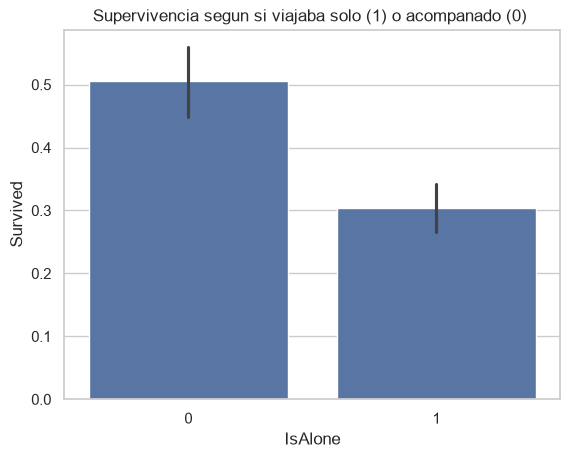

In [8]:
sns.barplot(data = df_prep, x="IsAlone", y="Survived")
plt.title("Supervivencia segun si viajaba solo (1) o acompanado (0) ")
plt.show()

In [9]:
df_prep["Sex"]= df_prep["Sex"].map({"male": 0, "female": 1})
df_prep[["Sex"]].head()

,Sex
0,0
1,1
2,1
3,1
4,0


In [10]:
df_prep = pd.get_dummies(df_prep, columns = ["Embarked"], prefix = "Embarked", drop_first=True)
df_prep.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,2,0,False,True
1,1,1,1,38.0,1,0,71.2833,2,0,False,False
2,1,3,1,26.0,0,0,7.9250,1,1,False,True
3,1,1,1,35.0,1,0,53.1000,2,0,False,True
4,0,3,0,35.0,0,0,8.0500,1,1,False,True


In [11]:
columnas_numericas = ["Age", "Fare", "FamilySize"]

scaler = StandardScaler()
df_prep[columnas_numericas] = scaler.fit_transform(df_prep[columnas_numericas])

df_prep[columnas_numericas].describe().round(2)

,Age,Fare,FamilySize
count,891.00,891.00,891.00
mean,0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-2.22,-0.65,-0.56
25%,-0.57,-0.49,-0.56
50%,-0.10,-0.36,-0.56
75%,0.43,-0.02,0.06
max,3.89,9.67,5.64


In [12]:
df_prep

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Embarked_Q,Embarked_S
0,0,3,0,-0.565736,1,0,-0.502445,0.059160,0,False,True
1,1,1,1,0.663861,1,0,0.786845,0.059160,0,False,False
2,1,3,1,-0.258337,0,0,-0.488854,-0.560975,1,False,True
3,1,1,1,0.433312,1,0,0.420730,0.059160,0,False,True
4,0,3,0,0.433312,0,0,-0.486337,-0.560975,1,False,True
...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,0,-0.181487,0,0,-0.386671,-0.560975,1,False,True
887,1,1,1,-0.796286,0,0,-0.044381,-0.560975,1,False,True
888,0,3,1,-0.104637,1,2,-0.176263,1.299429,0,False,True
889,1,1,0,-0.258337,0,0,-0.044381,-0.560975,1,False,False


In [13]:
x = df_prep.drop(columns=["Survived"])
y = df_prep["Survived"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Tamano fr x_train:", x_train.shape)
print("tamano de x_test:", x_test.shape)
print()
print("Porcion de sobrevivientes en y_train:", y_train.mean().round(3))
print("Porcion de sobrevivientes en y_test:", y_test.mean().round(3))

Tamano fr x_train: (712, 10)
tamano de x_test: (179, 10)

Porcion de sobrevivientes en y_train: 0.383
Porcion de sobrevivientes en y_test: 0.385


In [14]:
x_train.to_csv("x_train.csv", index=False)
x_test.to_csv("x_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

print("Archivos guardados: x_train.csv, x_test.csv, y_train.csv, y_test.csv")

Archivos guardados: x_train.csv, x_test.csv, y_train.csv, y_test.csv


In [20]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

def preparar_datos():
    # 1. Cargar el dataset original usando el nombre fijo
    df = pd.read_csv("titanic.csv")
    df_prep = df.copy()
    
    # 2. Tratamiento de valores nulos
    mediana_edad = df_prep["Age"].median()
    df_prep["Age"] = df_prep["Age"].fillna(mediana_edad)
    
    moda_embarque = df_prep["Embarked"].mode()[0]
    df_prep["Embarked"] = df_prep["Embarked"].fillna(moda_embarque)
    
    # 3. Eliminar columnas irrelevantes
    columnas_a_eliminar = ["PassengerId", "Name", "Ticket", "Cabin"]
    df_prep = df_prep.drop(columns=columnas_a_eliminar)
    
    # 4. Ingeniería de Características
    df_prep["FamilySize"] = df_prep["SibSp"] + df_prep["Parch"] + 1
    df_prep["IsAlone"] = (df_prep["FamilySize"] == 1).astype(int)
    
    # 5. Codificación de variables categóricas
    df_prep["Sex"] = df_prep["Sex"].map({"male": 0, "female": 1})
    df_prep = pd.get_dummies(df_prep, columns=["Embarked"], prefix="Embarked", drop_first=True)
    
    embarked_cols = [col for col in df_prep.columns if col.startswith("Embarked_")]
    df_prep[embarked_cols] = df_prep[embarked_cols].astype(int)
    
    # 6. Separar variables predictoras (X) y objetivo (y)
    X = df_prep.drop(columns=["Survived"])
    y = df_prep["Survived"]
    
    # 7. Escalado de variables numéricas
    columnas_numericas = ["Age", "Fare", "FamilySize"]
    scaler = StandardScaler()
    X[columnas_numericas] = scaler.fit_transform(X[columnas_numericas])
    
    # 8. División en conjuntos de entrenamiento y prueba
    X_train1, X_test1, y_train1, y_test1 = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )
    
    # 9. Guardar automáticamente los archivos en CSV (con las mayúsculas correctas)
    X_train1.to_csv("x_train1.csv", index=False)
    X_test1.to_csv("x_test1.csv", index=False)
    y_train1.to_csv("y_train1.csv", index=False)
    y_test1.to_csv("y_test1.csv", index=False)
    
    # 10. Mensaje de confirmación
    print("Archivos guardados: x_train1.csv, x_test1.csv, y_train1.csv, y_test1.csv")
    
    return X_train1, X_test1, y_train1, y_test1

In [21]:
X_train1, X_test1, y_train1, y_test1 = preparar_datos()

Archivos guardados: x_train1.csv, x_test1.csv, y_train1.csv, y_test1.csv
